### Superstore dataset Sales and Profitability Analysis

### Notebook 2: Sales and Profitability

### Objective

This notebook evaluates sales and profitability across categories,subcategories, regions and customer segments. 
It also investigates loss-making transactions
And lastly, the relationship between discounts and profit.

### Business Questions

1. Which categories and subcategories generated the highest sales and profit?
2. Where are losses concentrated across the business?
3. How are discounts associated with profitability?
4. Which high-sales transactions or products resulted into losses?

## 1. Setup and Project Paths

In [1]:
from pathlib import Path

# Importing pandas for loading and analysing tabular data.
import numpy as np

# Import NumPy for numerical checks such as np.isclose().
import pandas as pd


# To find the directory from which the notebook is running.

CURRENT_DIR = Path.cwd()


# If the notebook is running from the notebooks folder, move one level upward to locate the main project folder.

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR


# Define input and output folder locations.

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DATA_DIR = (
    PROJECT_ROOT / "data" / "processed"
)

TABLES_DIR = (
    PROJECT_ROOT / "results" / "tables"
)

FIGURES_DIR = (
    PROJECT_ROOT / "results" / "figures"
)


# Create the output folders.


for folder in [
    PROCESSED_DATA_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


In [2]:
# Checking whether all required project folders exist.

folder_check = pd.Series({
    "raw_data": RAW_DATA_DIR.exists(),
    "processed_data": PROCESSED_DATA_DIR.exists(),
    "tables": TABLES_DIR.exists(),
    "figures": FIGURES_DIR.exists()
})

folder_check

raw_data          True
processed_data    True
tables            True
figures           True
dtype: bool

In [3]:
# List only the files stored inside data/raw.
# This is to prevents filename assumptions and spelling mistakes.

raw_filenames = sorted(
    file.name
    for file in RAW_DATA_DIR.iterdir()
    if file.is_file()
)

raw_filenames

['orders.csv',
 'people.csv',
 'returns.csv',
 'sample_superstore.xlsx',
 '~$sample_superstore.xlsx']

In [4]:
# Defined the location of each raw source file.

ORDERS_FILE = (
    RAW_DATA_DIR / "sample_superstore.xlsx"
)

RETURNS_FILE = (
    RAW_DATA_DIR / "returns.csv"
)

PEOPLE_FILE = (
    RAW_DATA_DIR / "people.csv"
)

In [5]:
#  The orders worksheet from the Excel workbook is loaded.

orders = pd.read_excel(
    ORDERS_FILE,
    sheet_name="Orders"
)


# The returns.csv file is loaded.

returns_raw = pd.read_csv(
    RETURNS_FILE
)


# The regional-manager.csv file mapping is loaded.

people = pd.read_csv(
    PEOPLE_FILE
)

In [6]:
# Reconfirmed that the folder containing Notebook 1's output exists.

PROCESSED_DATA_DIR.exists()

True

## 2. Loading the Processed Dataset

In [7]:
# Redefining the reusable dataset created in Notebook 1.

PROCESSED_FILE = (
    PROCESSED_DATA_DIR / "orders_enriched.csv"
)


# Stop execution if Notebook 1's output cannot be found.

assert PROCESSED_FILE.exists(), (
    "orders_enriched.csv was not found."
)

In [8]:
# CSV files do not preserve pandas datetime data types.
# Parse_dates restores these two columns while loading.

orders_enriched = pd.read_csv(
    PROCESSED_FILE,
    parse_dates=[
        "Order Date",
        "Ship Date"
    ]
)

In [9]:
# ReConfirmed that the processed dataset has the original dimensions as prodcuced in notebbok 1.

orders_enriched.shape

(10194, 23)

In [10]:
orders_enriched[   ["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

## 3. Overall Business Performance

In [11]:
# Confirmed that loading the processed CSV preserved the correct financial totals.
# No output means both total-reconciliation assertions passed.
assert np.isclose(
    orders_enriched["Sales"].sum(),2326534.3543
)

assert np.isclose(
    orders_enriched["Profit"].sum(), 292296.8146
)

In [12]:
# Calculated and store the numeric KPI values.

kpi_summary = pd.Series({
    "Total Sales": (
        orders_enriched["Sales"].sum()
    ),

    "Total Profit": (
        orders_enriched["Profit"].sum()
    ),

    "Profit Margin (%)": (
        orders_enriched["Profit"].sum()
        / orders_enriched["Sales"].sum()
        * 100
    ),

    "Total Quantity": (
        orders_enriched["Quantity"].sum()
    ),

    "Unique Orders": (
        orders_enriched["Order ID"].nunique()
    ),

    "Unique Customers": (
        orders_enriched["Customer ID"].nunique()
    )
}, name="Value")

kpi_summary

Total Sales          2.326534e+06
Total Profit         2.922968e+05
Profit Margin (%)    1.256361e+01
Total Quantity       3.865400e+04
Unique Orders        5.111000e+03
Unique Customers     8.040000e+02
Name: Value, dtype: float64

In [13]:
# KPI summary of overall metrics that provide context  for the detailed profitability analysis.
# ,.0f = comma separators with zero decimal places
# .2f  = two decimal places


kpi_display = pd.Series({
    "Total Sales": (
        f"{kpi_summary['Total Sales']:,.0f}"
    ),

    "Total Profit": (
        f"{kpi_summary['Total Profit']:,.0f}"
    ),

    "Profit Margin": (
        f"{kpi_summary['Profit Margin (%)']:.2f}%"
    ),

    "Total Quantity": (
        f"{kpi_summary['Total Quantity']:,.0f}"
    ),

    "Unique Orders": (
        f"{kpi_summary['Unique Orders']:,.0f}"
    ),

    "Unique Customers": (
        f"{kpi_summary['Unique Customers']:,.0f}"
    )
}, name="Value")

kpi_display

Total Sales         2,326,534
Total Profit          292,297
Profit Margin          12.56%
Total Quantity         38,654
Unique Orders           5,111
Unique Customers          804
Name: Value, dtype: str

### Initial Observations

The business generated approximately 2.33 million in sales and 292.30 thousand in profit, resulting in an overall profit margin of
approximately 12.56%. These totals cover 5,111 unique orders placed by 804 customers.

## 4. Category level Performance

In [14]:
# Aggregated results  by product category.

category_performance = (
    orders_enriched
    .groupby(
        "Category",
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
)

In [15]:
# Profit margin shows how much profit was earned for every 100 units of sales.

category_performance["Profit_Margin_percent"] = (
    category_performance["Total_Profit"]
    / category_performance["Total_Sales"]
    * 100
)

In [16]:
# Arrange the most profitable category first.

category_performance = (
    category_performance
    .sort_values(
        "Total_Profit",
        ascending=False
    )
    .reset_index(drop=True)
)

In [17]:
# Reverifying the total sales,total profit and total quantity in category performance with kpi summaryfor consistency purpose.
# No output indicates there's no mismatch in figures 

assert np.isclose(
    category_performance["Total_Sales"].sum(),
    kpi_summary["Total Sales"]
)



assert np.isclose(
    category_performance["Total_Profit"].sum(),
    kpi_summary["Total Profit"]
)



assert np.isclose(
    category_performance["Total_Quantity"].sum(),
    kpi_summary["Total Quantity"]
)

In [18]:
#  category level performance of sales and profitability.

category_display = (
    category_performance
    .style
    .format({
        "Total_Sales": "{:,.0f}",
        "Total_Profit": "{:,.0f}",
        "Total_Quantity": "{:,.0f}",
        "Unique_Orders": "{:,.0f}",
        "Average_Discount": "{:.2%}",
        "Profit_Margin_percent": "{:.2f}%"
    })
)

category_display

,Category,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Average_Discount,Profit_Margin_percent
0,Technology,"839,893","146,543","7,017","1,560",13.15%,17.45%
1,Office Supplies,"731,893","126,023","23,268","3,812",15.63%,17.22%
2,Furniture,"754,748","19,730","8,369","1,819",17.30%,2.61%


## 5. Subcategory Performance

In [19]:
# Aggregated performance at Category and Sub-Category level.

# Category is retained so every subcategory remains connected  to its parent product category.

subcategory_performance = (
    orders_enriched
    .groupby(
        ["Category", "Sub-Category"],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
)

In [20]:
# Calculating the percentage of sales retained as profit.

subcategory_performance["Profit_Margin_percent"] = (
    subcategory_performance["Total_Profit"]
    / subcategory_performance["Total_Sales"]
    * 100
)

In [21]:
subcategory_performance.shape

(17, 8)

In [22]:
# Reconcilation of Subcategory sales with its overall sales.

assert np.isclose(
    subcategory_performance["Total_Sales"].sum(),
    kpi_summary["Total Sales"]
)


# Subcategory profit must reconcile with overall profit.

assert np.isclose(
    subcategory_performance["Total_Profit"].sum(),
    kpi_summary["Total Profit"]
)


# Subcategory quantity must reconcile with overall quantity.

assert np.isclose(
    subcategory_performance["Total_Quantity"].sum(),
    kpi_summary["Total Quantity"]
)

In [23]:
# Reuse np.where() to differentiate between profitable and  loss-making subcategories without adding  arbitrary thresholds.

subcategory_performance["Profit_Status"] = np.where(
    subcategory_performance["Total_Profit"] < 0,
    "Loss-making",
    "Profitable"
)

In [24]:
subcategory_performance[
    "Profit_Status"
].value_counts()

Profit_Status
Profitable     14
Loss-making     3
Name: count, dtype: int64

In [25]:
# Identifing the strongest and weakest subcategories by its total profit

loss_making_subcategories = (
    subcategory_performance
    .loc[
        subcategory_performance["Total_Profit"] < 0
    ]
    .sort_values(
        "Total_Profit",
        ascending=True
    )
)

In [26]:
# Displaying Highest loss making sub category
loss_making_subcategories.style.format({
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Total_Quantity": "{:,.0f}",
    "Unique_Orders": "{:,.0f}",
    "Average_Discount": "{:.2%}",
    "Profit_Margin_percent": "{:.2f}%"
})

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Average_Discount,Profit_Margin_percent,Profit_Status
3,Furniture,Tables,"208,020","-17,753","1,261",314,25.81%,-8.53%,Loss-making
0,Furniture,Bookcases,"115,361","-3,632",878,228,21.53%,-3.15%,Loss-making
12,Office Supplies,Supplies,"46,725","-1,171",653,189,7.60%,-2.51%,Loss-making


In [27]:
# nlargest returns 5 the highest Total_Profit values.

top_5_profitable_subcategories = (
    subcategory_performance
    .nlargest(
        5,
        "Total_Profit"
    )
)

In [28]:
# Displaying Highest profit  making sub category
top_5_profitable_subcategories.style.format({
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Total_Quantity": "{:,.0f}",
    "Unique_Orders": "{:,.0f}",
    "Average_Discount": "{:.2%}",
    "Profit_Margin_percent": "{:.2f}%"
})

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Average_Discount,Profit_Margin_percent,Profit_Status
14,Technology,Copiers,"150,745","56,094",242,70,15.71%,37.21%,Profitable
16,Technology,Phones,"331,843","45,051","3,357",826,15.26%,13.58%,Profitable
13,Technology,Accessories,"167,380","41,937","2,976",718,7.85%,25.05%,Profitable
10,Office Supplies,Paper,"79,541","34,512","5,207","1,205",7.50%,43.39%,Profitable
6,Office Supplies,Binders,"207,355","31,426","6,071","1,339",36.91%,15.16%,Profitable


In [29]:
# Identifying the highest profit margin.

highest_margin_profitable_subcategory = (
    subcategory_performance
    .loc[
        subcategory_performance["Total_Profit"] > 0
    ]
    .nlargest(
        5,
        "Profit_Margin_percent"
    )
)

highest_margin_profitable_subcategory.style.format()


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Average_Discount,Profit_Margin_percent,Profit_Status
9,Office Supplies,Labels,12695.042000,5572.778000,1410,348,0.070924,43.897279,Profitable
10,Office Supplies,Paper,79540.538000,34511.507000,5207,1205,0.075000,43.388576,Profitable
7,Office Supplies,Envelopes,16528.362000,6988.024700,914,251,0.079688,42.278991,Profitable
14,Technology,Copiers,150745.290000,56093.936500,242,70,0.157143,37.211071,Profitable
8,Office Supplies,Fasteners,8532.240000,2428.635800,980,226,0.078603,28.464223,Profitable


### Initial Observations

- Of the 17 subcategories, 14 generated an overall profit and three generated an overall loss.
- Tables produced the largest total loss of approximately 17,753, followed by Bookcases and Supplies.
- Copiers generated the highest total profit of approximately 56,094.
- Labels had the highest profit margin at approximately 43.90%, but it did not generate the highest total profit.
- No conclusion about the relationship between discounts and profitability has been established at this stage.

## 6. Subcategory Profit Visualization

In [30]:
# Matplotlib controls figures, axes and file saving.
import matplotlib.pyplot as plt

# Seaborn provides statistical visualization functions.
import seaborn as sns

In [31]:
# Applying  a clean theme to subsequent charts.
# style="whitegrid"
# compare positive and negative profit values.

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

In [32]:
# Sorted the subcategory from highest to lowest total profit.
# .copy() to keep the chart data independent from the main table.

subcategory_profit_plot = (
    subcategory_performance
    .sort_values(
        "Total_Profit",
        ascending=False
    )
    .copy()
)

In [33]:
# Green represents profitable subcategories.
# Red represents loss-making subcategories.

profit_status_palette = {
    "Profitable": "#2E8B57",
    "Loss-making": "#C44E52"
}

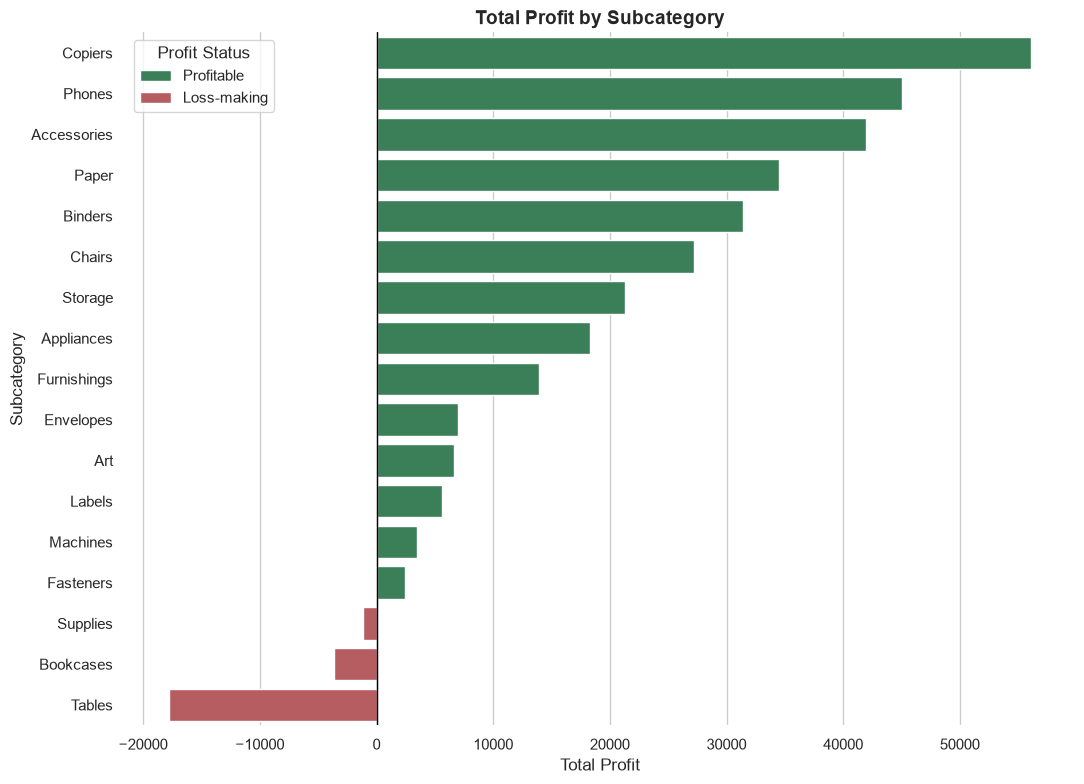

In [34]:
# To create the figure and axes.
# 17 subcategory names.

fig, ax = plt.subplots(
    figsize=(11, 8)
)


# Ploting total profit by subcategory.
# estimator="sum" specifies that the plotted value represents total profit.
# errorbar=None removes confidence intervals because the input table already contains one aggregated row per subcategory.

sns.barplot(
    data=subcategory_profit_plot,
    x="Total_Profit",
    y="Sub-Category",
    hue="Profit_Status",
    order=subcategory_profit_plot["Sub-Category"],
    estimator="sum",
    errorbar=None,
    dodge=False,
    palette=profit_status_palette,
    ax=ax
)


# Added a reference line at zero.
# Bars to the left represent losses.

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)


# Appropriate Labels and formatting  for the chart.

ax.set_title(
    "Total Profit by Subcategory",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Total Profit")
ax.set_ylabel("Subcategory")


# Keep the legend title clear.

ax.legend(
    title="Profit Status"
)


# To remove unnecessary chart borders.

sns.despine(
    left=True,
    bottom=True
)


# Adjust spacing so labels are not cut off.

fig.tight_layout()

In [35]:
# Defining the reusable chart-file location.

SUBCATEGORY_PROFIT_FIGURE = (
    FIGURES_DIR / "subcategory_total_profit.png"
)


# dpi=300 creates a sharp image.
# bbox_inches="tight" prevents labels from being clipped.

fig.savefig(
    SUBCATEGORY_PROFIT_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
SUBCATEGORY_PROFIT_FIGURE.exists()

True

## 7. Discount and Profitability Analysis

In [37]:
# Reconfirmed that every discount is stored between 0 and 1.

assert orders_enriched["Discount"].between(0, 1).all()

# Work on a copy so the original processed dataset remains unchanged.
orders_discount = orders_enriched.copy()

# Divide the Discount column into business ranges.
orders_discount["Discount_Band"] = pd.cut(
    orders_discount["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.00],
    labels=[
        "No discount",
        ">0% to 10%",
        ">10% to 20%",
        ">20% to 30%",
        ">30% to 50%",
        ">50%"
    ],
    right=True,
    include_lowest=True
)

# Checking whether every row received a discount band.
orders_discount["Discount_Band"].isna().sum()

np.int64(0)

In [38]:
discount_performance = (
    orders_discount
    .groupby(
        "Discount_Band",
        observed=True,
        as_index=False
    )
    .agg(
        Record_Count=("Profit", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),

        # To count rows where the individual line transaction made a loss.
        Loss_Making_Rows=("Profit", lambda values: values.lt(0).sum())
    )
)

# Calculating  profit relative to sales for each discount band.
discount_performance["Profit_Margin_percent"] = (
    discount_performance["Total_Profit"]
    / discount_performance["Total_Sales"]
    * 100
)

# Calculatimg the percentage of rows that made a loss.
discount_performance["Loss_Row_percent"] = (
    discount_performance["Loss_Making_Rows"]
    / discount_performance["Record_Count"]
    * 100
)



In [39]:
# Reconfirming that total sales,total profit and total record count matches with the figures given in origianl dataset orders discount
# No output indicates there's no mismatch in the calcuated figures.
assert np.isclose(
    discount_performance["Total_Sales"].sum(),
    orders_discount["Sales"].sum()
)

# The grouped profit must equal the original total profit.
assert np.isclose(
    discount_performance["Total_Profit"].sum(),
    orders_discount["Profit"].sum()
)

# Every source row must be represented in the summary.
assert (
    discount_performance["Record_Count"].sum()
    == len(orders_discount)
)

In [40]:
## Cleaned analysis with respect to defiend discount bands
discount_performance.style.format({
    "Record_Count": "{:,.0f}",
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Average_Profit": "{:,.2f}",
    "Loss_Making_Rows": "{:,.0f}",
    "Profit_Margin_percent": "{:.2f}%",
    "Loss_Row_percent": "{:.2f}%"
})

,Discount_Band,Record_Count,Total_Sales,Total_Profit,Average_Profit,Loss_Making_Rows,Profit_Margin_percent,Loss_Row_percent
0,No discount,"4,925","1,105,324","326,719",66.34,0,29.56%,0.00%
1,>0% to 10%,96,"54,952","9,100",94.79,4,16.56%,4.17%
2,>10% to 20%,"3,758","801,498","92,499",24.61,527,11.54%,14.02%
3,>20% to 30%,230,"104,474","-10,513",-45.71,211,-10.06%,91.74%
4,>30% to 50%,311,"195,395","-48,477",-155.87,285,-24.81%,91.64%
5,>50%,874,"64,891","-77,030",-88.14,874,-118.71%,100.00%


In [41]:
# A seperate plotting copy
# This keeps discount_performance unchanged.
discount_plot = discount_performance.copy()

# Converted the categorical bands to strings for chart labels.
discount_plot["Discount_Band"] = (
    discount_plot["Discount_Band"].astype(str)
)

# Classified each band according to its total profit.
discount_plot["Profit_Status"] = np.where(
    discount_plot["Total_Profit"] >= 0,
    "Profitable",
    "Loss-making"
)

discount_order = discount_plot["Discount_Band"].tolist()

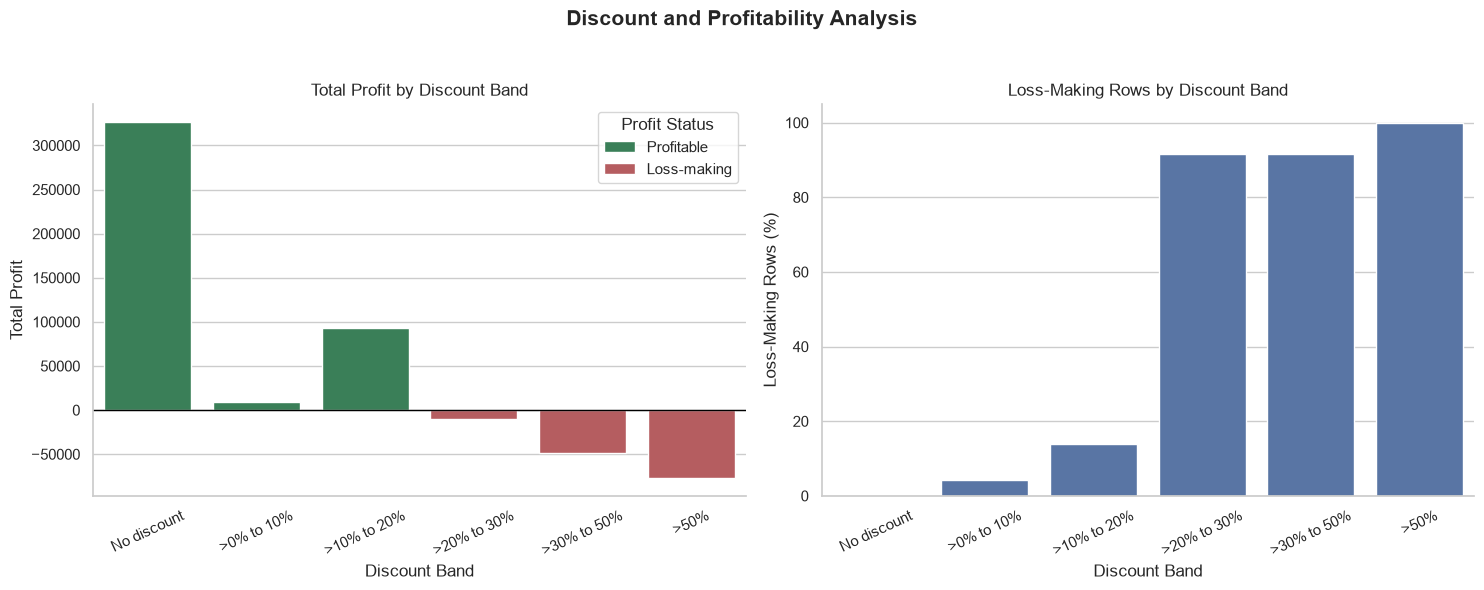

In [42]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6)
)

# Chart 1: Total profit generated by each discount band.
sns.barplot(
    data=discount_plot,
    x="Discount_Band",
    y="Total_Profit",
    hue="Profit_Status",
    order=discount_order,
    estimator="sum",
    errorbar=None,
    dodge=False,
    palette={
        "Profitable": "#2E8B57",
        "Loss-making": "#C44E52"
    },
    ax=axes[0]
)

axes[0].axhline(
    y=0,
    color="black",
    linewidth=1
)

axes[0].set_title("Total Profit by Discount Band")
axes[0].set_xlabel("Discount Band")
axes[0].set_ylabel("Total Profit")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Profit Status")


# Chart 2: Percentage of rows producing a loss.
sns.barplot(
    data=discount_plot,
    x="Discount_Band",
    y="Loss_Row_percent",
    order=discount_order,
    estimator="sum",
    errorbar=None,
    color="#4C72B0",
    ax=axes[1]
)

axes[1].set_title("Loss-Making Rows by Discount Band")
axes[1].set_xlabel("Discount Band")
axes[1].set_ylabel("Loss-Making Rows (%)")
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis="x", rotation=25)

fig.suptitle(
    "Discount and Profitability Analysis",
    fontsize=15,
    fontweight="bold"
)

sns.despine()
fig.tight_layout(rect=[0, 0, 1, 0.95])

In [43]:
#Saving the visualizations
DISCOUNT_PROFITABILITY_FIGURE = (
    FIGURES_DIR / "discount_profitability.png"
)

fig.savefig(
    DISCOUNT_PROFITABILITY_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

DISCOUNT_PROFITABILITY_FIGURE.exists()

True

### Initial Observations

- Total profit remains positive for discount bands up to and including 20%. It becomes negative when discounts exceed > 20%.
- The percentage of loss-making rows shows a substantial increase after the 20% threshold. The loss-row rate rises from 14.02% in the `>10% to 20%` band to 91.74% in the `>20% to 30%` band.
- Approximately 91.64% of rows in the `>30% to 50%` band are loss-making, while every row in the `>50%` band produces a loss.
- The no-discount band generates the highest total profit and contains no loss-making rows. However, it also contains the largest number of records, so total profit alone cannot isolate the effect of discounting.
- The results show a strong descriptive association between discounts above 20% and weaker profitability. But they do not prove that discounts caused the losses because differences in sales volume, product mix,region and other factors were not controlled.

## 8. Regional and Manager Performance

In [44]:
# Aggregated business performance for each region and its manager.
regional_performance = (
    orders_enriched
    .groupby(
        ["Region", "Regional Manager"],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
)

In [45]:
# Calculating profit margins for each region and its regional manager
regional_performance["Profit_Margin_percent"] = (
    regional_performance["Total_Profit"]
    / regional_performance["Total_Sales"]
    * 100
)

# Ranking each regions independently by sales and profit.
regional_performance["Sales_Rank"] = (
    regional_performance["Total_Sales"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

regional_performance["Profit_Rank"] = (
    regional_performance["Total_Profit"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# Rearranged the table from highest to lowest total profit.
regional_performance = (
    regional_performance
    .sort_values("Total_Profit", ascending=False)
    .reset_index(drop=True)
)

In [46]:
# Reconcliation of total sales and total profit with orginal dataset
assert np.isclose(
    regional_performance["Total_Sales"].sum(),
    orders_enriched["Sales"].sum()
)

assert np.isclose(
    regional_performance["Total_Profit"].sum(),
    orders_enriched["Profit"].sum()
)

# Every region will have a regional manager after the Notebook 1 merge.
assert regional_performance["Regional Manager"].notna().all()

regional_performance.style.format({
    "Total_Sales": "{:,.0f}",
    "Total_Profit": "{:,.0f}",
    "Total_Quantity": "{:,.0f}",
    "Unique_Orders": "{:,.0f}",
    "Unique_Customers": "{:,.0f}",
    "Average_Discount": "{:.2%}",
    "Profit_Margin_percent": "{:.2f}%"
})

,Region,Regional Manager,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Unique_Customers,Average_Discount,Profit_Margin_percent,Sales_Rank,Profit_Rank
0,West,Sadie Pawthorne,"739,814","110,799","12,466","1,635",686,10.89%,14.98%,1,1
1,East,Chuck Magee,"691,828","94,883","11,159","1,475",685,14.34%,13.71%,2,2
2,South,Fred Suzuki,"391,722","46,749","6,209",822,512,14.73%,11.93%,4,3
3,Central,Roxanne Rodriguez,"503,171","39,865","8,820","1,179",629,24.10%,7.92%,3,4


## 9. Regional Sales and Profit Visualization

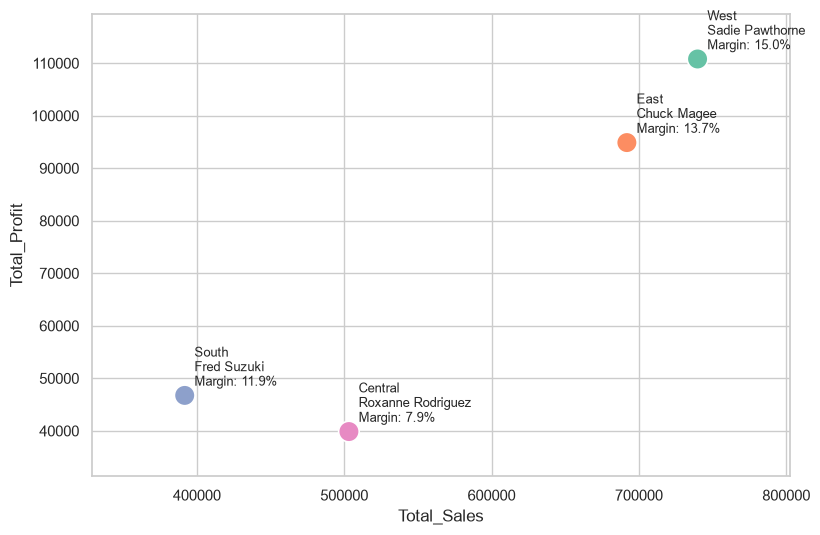

In [47]:
#  A scatter plot to compare regional sales and profit.
fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=regional_performance,
    x="Total_Sales",
    y="Total_Profit",
    hue="Region",
    s=220,                  # Fixed marker size
    palette="Set2",
    ax=ax,
    legend=False          
)

# Label every point with its region, manager and profit margin.
for _, row in regional_performance.iterrows():
    ax.annotate(
        text=(
            f"{row['Region']}\n"
            f"{row['Regional Manager']}\n"
            f"Margin: {row['Profit_Margin_percent']:.1f}%"
        ),
        xy=(row["Total_Sales"], row["Total_Profit"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )

# Add space around the points so longer labels are not clipped.
ax.margins(x=0.18, y=0.12)

In [48]:
#Saving the visualizations
REGIONAL_SALES_PROFIT_FIGURE = (
    FIGURES_DIR / "regional_sales_vs_profit.png"
)

fig.savefig(
    REGIONAL_SALES_PROFIT_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

REGIONAL_SALES_PROFIT_FIGURE.exists()

True

### Initial Observations

- The West region leads in both total sales and total profit, ranking first on both measures.
- The South region ranks fourth in sales but third in profit, indicating comparatively stronger profit performance than its sales volume alone suggests.
- The Central region has the highest average discount at 24.10% and the lowest profit margin at 7.92%. Despite ranking third in sales, it ranks fourth in profit.
- These results show a descriptive association between higher average discounts and weaker regional profitability.
    Therefore, neither statistical correlation nor causation can be claimed. 
    Differences in product mix and customer mix  may also influence regional profitability.

In [49]:
# Defining  reusable locations for summary tables.
KPI_SUMMARY_FILE = TABLES_DIR / "kpi_summary.csv"
CATEGORY_PERFORMANCE_FILE = TABLES_DIR / "category_performance.csv"
SUBCATEGORY_PERFORMANCE_FILE = TABLES_DIR / "subcategory_performance.csv"
DISCOUNT_PERFORMANCE_FILE = TABLES_DIR / "discount_performance.csv"
REGIONAL_PERFORMANCE_FILE = TABLES_DIR / "regional_performance.csv"

In [50]:
# Converting the Kpi summary  into a two-column DataFrame before exporting.
kpi_summary_export = (
    kpi_summary
    .rename_axis("KPI")
    .reset_index(name="Value")
)

kpi_summary_export.to_csv(
    KPI_SUMMARY_FILE,
    index=False
)

category_performance.to_csv(
    CATEGORY_PERFORMANCE_FILE,
    index=False
)

subcategory_performance.to_csv(
    SUBCATEGORY_PERFORMANCE_FILE,
    index=False
)

discount_performance.to_csv(
    DISCOUNT_PERFORMANCE_FILE,
    index=False
)

regional_performance.to_csv(
    REGIONAL_PERFORMANCE_FILE,
    index=False
)

In [51]:
# Stored the files in a dictionary so they can be checked together.
exported_table_files = {
    "KPI summary": KPI_SUMMARY_FILE,
    "Category performance": CATEGORY_PERFORMANCE_FILE,
    "Subcategory performance": SUBCATEGORY_PERFORMANCE_FILE,
    "Discount performance": DISCOUNT_PERFORMANCE_FILE,
    "Regional performance": REGIONAL_PERFORMANCE_FILE
}

# Check whether every saved file exists.
export_status = pd.Series(
    {
        table_name: file_path.exists()
        for table_name, file_path in exported_table_files.items()
    },
    name="File_Exists"
)

assert export_status.all()

export_status

KPI summary                True
Category performance       True
Subcategory performance    True
Discount performance       True
Regional performance       True
Name: File_Exists, dtype: bool

## 10. Executive Summary 

### Overall Performance

- The business generated approximately 2.33 million in sales and 292,297 in profit, resulting in an overall profit margin of approximately 12.56%.
- These results were generated from 5,111 unique orders and 804 unique customers.

### Category and Subcategory Performance

- Technology generated the highest total sales and profit, with approximately 839,893 in sales and 146,543 in profit.
- Office Supplies generated approximately 126,023 in profit and maintained a profit margin similar to Technology.
- Furniture generated substantial sales but only approximately 19,730 in profit, producing the lowest category-level profit margin at 2.61%.
- Copiers generated the highest total profit among subcategories, while Labels produced the highest profit margin.
- Tables generated the largest subcategory loss, followed by Bookcases and Supplies.

### Discount Performance

- Profit remained positive for discount bands up to 20% but became negative above the 20% discount level.
- More than 91% of rows in each discount band above 20% were loss-making.
- Every row in the discount band above 50% produced a loss.
- These findings indicate a strong descriptive relationship but do not establish that discounting alone caused the losses.

### Regional Performance

- West ranked first in both sales and profit and produced the highest regional profit margin.
- East ranked second in both sales and profit.
- South ranked fourth in sales but third in profit.
- Central ranked third in sales but fourth in profit. It also had the highest average discount and lowest regional profit margin.
- Regional results should not be treated as direct evaluations of individual managers because differences there's no data on market conditons and other factors like  product mix and customers.